In [1]:
import numpy as np
import matplotlib.pyplot as plt

<h3> Exercise 2.3: Part b) </h3>

In [2]:
def heun_method(lam, h, x0=1.0, T=1.0):

    N = int(round(T / h))
    h = T / N

    t = np.linspace(0, T, N + 1)
    x = np.zeros(N + 1)

    x[0] = x0

    for n in range(N):
        x[n + 1] = 1/2*(1 + (1-(lam*h))**2)*x[n]

    return t, x

In [4]:
k_values = np.arange(1, 11)
h_values = 2.0 ** (-k_values)

errors = []

for h in h_values:

    t, x = heun_method(lam=1, h=h)

    x_exact_final = np.exp(-1)
    x_numerical_final = x[-1]

    error = abs(x_exact_final - x_numerical_final)

    errors.append(error)

errors = np.array(errors)

print("Step size h       Global error")
print("--------------------------------")

for h, error in zip(h_values, errors):
    print(f"{h:<18.8f}{error:.8e}")

Step size h       Global error
--------------------------------
0.50000000        2.27455588e-02
0.25000000        4.64958867e-03
0.12500000        1.05380291e-03
0.06250000        2.51097545e-04
0.03125000        6.13022024e-05
0.01562500        1.51458794e-05
0.00781250        3.76427830e-06
0.00390625        9.38312193e-07
0.00195312        2.34234407e-07
0.00097656        5.85157095e-08


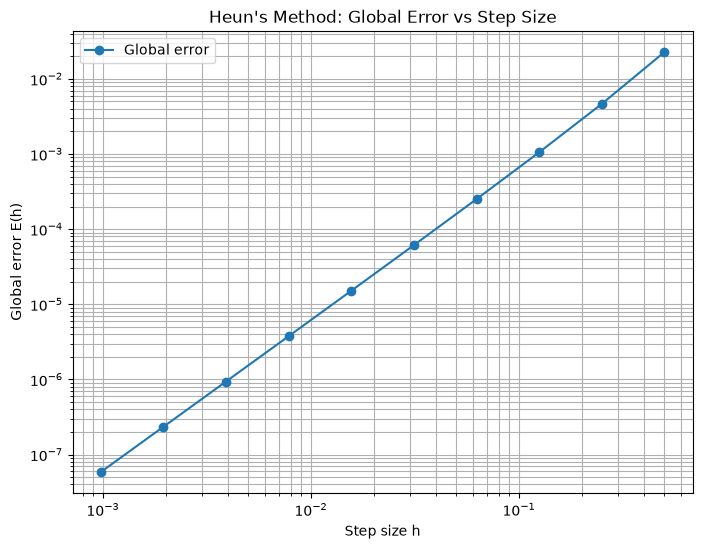

In [5]:
plt.figure(figsize=(8, 6))

plt.loglog(h_values, errors, 'o-', label='Global error')

plt.xlabel('Step size h')
plt.ylabel('Global error E(h)')
plt.title('Heun\'s Method: Global Error vs Step Size')

plt.grid(True, which='both')
plt.legend()

plt.show()

In [6]:
log_h = np.log(h_values)
log_errors = np.log(errors)

slope, intercept = np.polyfit(log_h, log_errors, 1)

print(f"Estimated convergence order: {slope:.4f}")

Estimated convergence order: 2.0480
